In [1]:
import pandas as pd
import numpy as np

In [2]:
dados = pd.read_csv('/Users/samuelmacedo/Projetos/exercicios_ml/clustering/dados/dados_mkt.csv')

dados.head()



,sexo,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,...,musica,rock,cabelo,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas
0,F,27,49,0,0,10,0,0,10,0,...,0,0,0,0,0,0,0,0,0,10
1,F,27,41,0,0,0,0,0,0,0,...,10,20,40,0,10,0,0,0,0,10
2,F,26,1,0,0,0,0,0,10,0,...,10,0,50,0,0,0,30,0,0,0
3,M,28,32,0,50,0,0,0,0,0,...,10,10,0,0,0,0,0,0,0,0
4,M,28,18,0,0,0,0,0,0,0,...,0,0,0,0,0,0,10,0,0,0


In [3]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 12992 entries, 0 to 12991
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   sexo               12992 non-null  str  
 1   idade              12992 non-null  int64
 2   numero_de_amigos   12992 non-null  int64
 3   basquete           12992 non-null  int64
 4   futebol_americano  12992 non-null  int64
 5   futebol            12992 non-null  int64
 6   softbol            12992 non-null  int64
 7   voleibol           12992 non-null  int64
 8   natacao            12992 non-null  int64
 9   animacao           12992 non-null  int64
 10  beisebol           12992 non-null  int64
 11  tenis              12992 non-null  int64
 12  esportes           12992 non-null  int64
 13  fofo               12992 non-null  int64
 14  danca              12992 non-null  int64
 15  banda              12992 non-null  int64
 16  marcha             12992 non-null  int64
 17  musica             1299

In [4]:
dados['sexo'].unique()



<ArrowStringArray>
['F', 'M', 'NE']
Length: 3, dtype: str

In [5]:
colunas = dados['sexo'].unique()


In [6]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(categories=[colunas], sparse_output=False)

encoded_sexo = encoder.fit_transform(X=dados[['sexo']])

In [7]:
df_encoded = pd.DataFrame(encoded_sexo, columns=encoder.get_feature_names_out(['sexo']))
df_encoded.head()

,sexo_F,sexo_M,sexo_NE
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,1.0,0.0
4,0.0,1.0,0.0


In [8]:
dados = pd.concat([dados, df_encoded], axis=1)
dados.drop(inplace=True, columns=['sexo'])

dados

/var/folders/_b/dnfcy9r13xvd5mtb_y7ckyd80000gn/T/ipykernel_32443/1835181126.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dados.drop(inplace=True, columns=['sexo'])


,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_F,sexo_M,sexo_NE
0,27,49,0,0,10,0,0,10,0,0,...,0,0,0,0,0,0,10,1.0,0.0,0.0
1,27,41,0,0,0,0,0,0,0,10,...,0,10,0,0,0,0,10,1.0,0.0,0.0
2,26,1,0,0,0,0,0,10,0,0,...,0,0,0,30,0,0,0,1.0,0.0,0.0
3,28,32,0,50,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.0,1.0,0.0
4,28,18,0,0,0,0,0,0,0,0,...,0,0,0,10,0,0,0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12987,26,21,0,0,0,0,0,0,0,0,...,0,0,0,20,0,0,0,1.0,0.0,0.0
12988,26,50,0,0,0,0,0,0,0,10,...,0,0,0,0,0,0,0,1.0,0.0,0.0
12989,27,32,0,0,0,0,0,0,10,0,...,0,0,0,0,0,0,0,1.0,0.0,0.0
12990,27,20,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1.0,0.0,0.0


In [9]:
import joblib

joblib.dump(encoder, 'encoder_sexo.pkl')

['encoder_sexo.pkl']

In [10]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

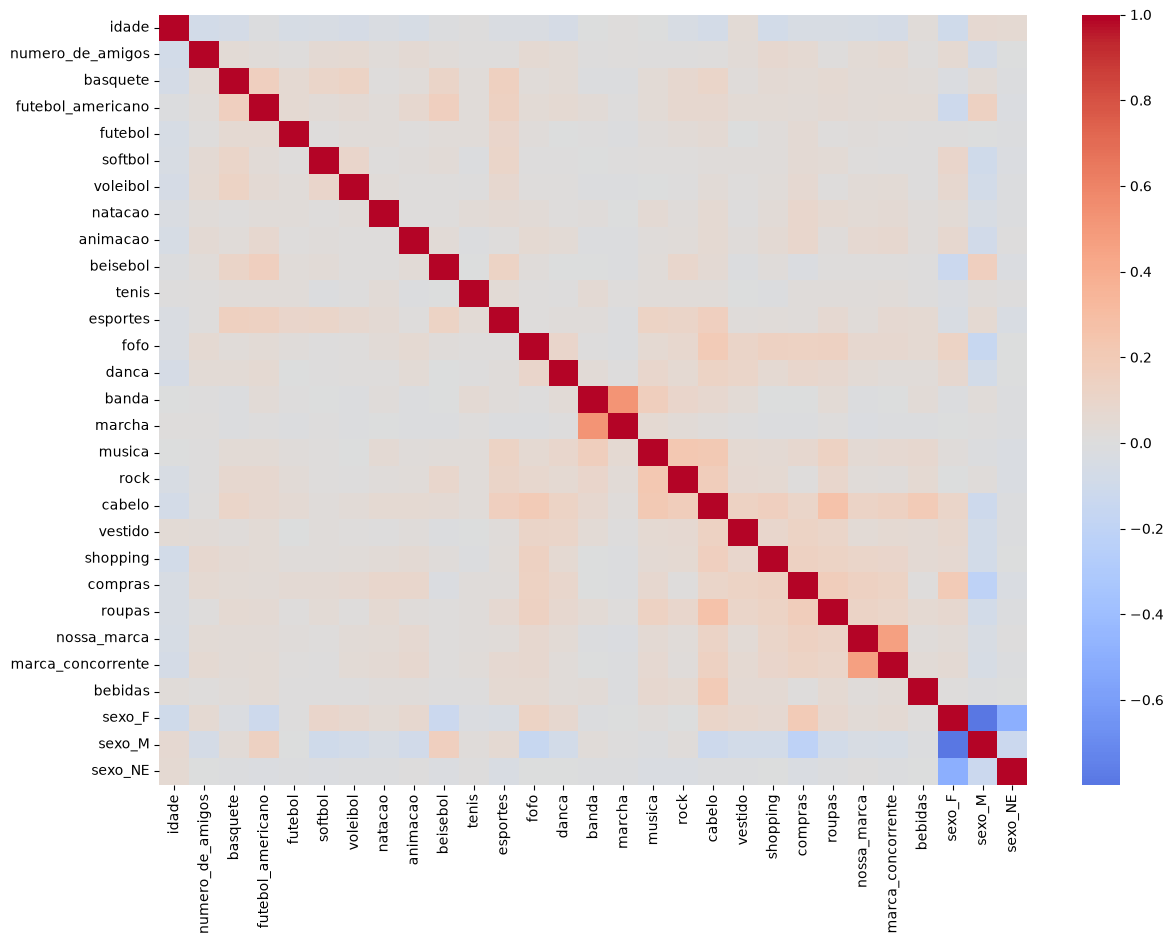

In [12]:
dados_numericos = dados.select_dtypes(include='number')

plt.figure(figsize=(14, 10))
sns.heatmap(dados_numericos.corr(), cmap='coolwarm', center=0)
plt.show()

In [13]:
dados.columns

Index(['idade', 'numero_de_amigos', 'basquete', 'futebol_americano', 'futebol',
       'softbol', 'voleibol', 'natacao', 'animacao', 'beisebol', 'tenis',
       'esportes', 'fofo', 'danca', 'banda', 'marcha', 'musica', 'rock',
       'cabelo', 'vestido', 'shopping', 'compras', 'roupas', 'nossa_marca',
       'marca_concorrente', 'bebidas', 'sexo_F', 'sexo_M', 'sexo_NE'],
      dtype='str')

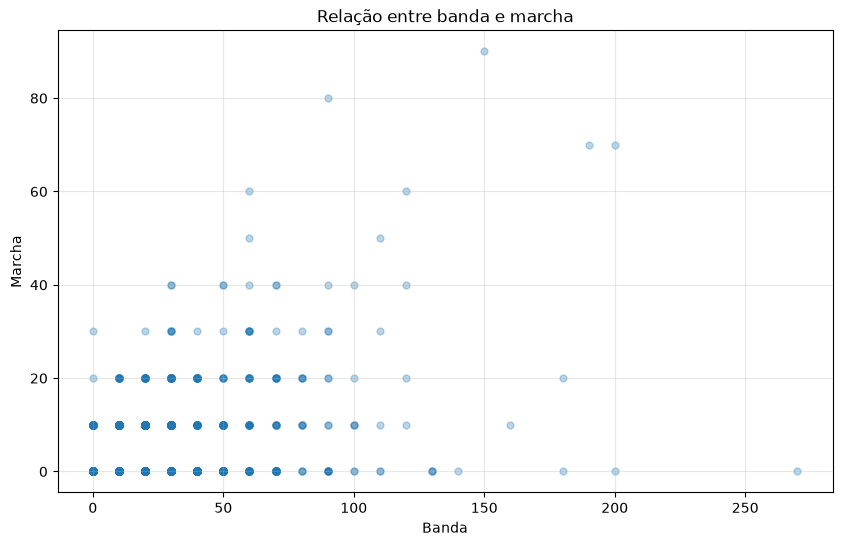

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    dados["banda"],
    dados["marcha"],
    alpha=0.3,
    s=25
)

plt.xlabel("Banda")
plt.ylabel("Marcha")
plt.title("Relação entre banda e marcha")
plt.grid(alpha=0.3)
plt.show()

In [18]:
dados[['marcha', 'banda']].corr()

,marcha,banda
marcha,1.000000,0.528058
banda,0.528058,1.000000


In [26]:
mod_kmeans = KMeans(n_clusters=2, random_state=45)

modelo = mod_kmeans.fit(dados)



In [30]:
mod_kmeans

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",45
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 29)","

In [31]:
mod_kmeans.inertia_

24912957.594588578

In [34]:
from sklearn.metrics import silhouette_score

silhouette_score(dados, mod_kmeans.predict(dados))

0.37997158863020164

In [35]:
def avaliacao(dados):
  inercia = []
  silhueta = []

  for k in range(2,21):
    kmeans = KMeans(n_clusters=k, random_state=45, n_init='auto')
    kmeans.fit(dados)
    inercia.append(kmeans.inertia_)
    silhueta.append(f'k={k} - '+ str(silhouette_score(dados, kmeans.predict(dados))))
  return silhueta, inercia

In [39]:
silhueta, inercia = avaliacao(dados)

In [37]:
silhueta

['k=2 - 0.37997158863020164',
 'k=3 - 0.2631947012216279',
 'k=4 - 0.27497370057197046',
 'k=5 - 0.2762790287828939',
 'k=6 - 0.2814107923103627',
 'k=7 - 0.19566339131554092',
 'k=8 - 0.12271514125212872',
 'k=9 - 0.1281093701405103',
 'k=10 - 0.13020718009107707',
 'k=11 - 0.13209306347804023',
 'k=12 - 0.09015815350273831',
 'k=13 - 0.09002551845716941',
 'k=14 - 0.08959066111262458',
 'k=15 - 0.09427696863257996',
 'k=16 - 0.09552364235312875',
 'k=17 - 0.09543714624178481',
 'k=18 - 0.08844412672288283',
 'k=19 - 0.0844173588143633',
 'k=20 - 0.08484109789709748']

In [41]:
inercia

[24912957.594588578,
 21861102.60949886,
 20611918.83360476,
 19790413.438039847,
 18972018.65055588,
 17737549.6157676,
 17445083.861588962,
 16683649.718693905,
 16069096.090546772,
 15629929.575900715,
 15339413.09862184,
 15090959.275861528,
 14806363.370104825,
 14597982.51753576,
 14444937.941286284,
 14253230.534250122,
 14011173.582026722,
 13768426.341053538,
 13509141.06826085]

In [42]:
import matplotlib.cm as cm
from sklearn.metrics import silhouette_samples

def graf_silhueta (n_clusters, dados):

  # Aplica o KMeans ao conjunto de dados
  kmeans = KMeans(n_clusters=n_clusters, random_state=45, n_init = 'auto')
  cluster_previsoes = kmeans.fit_predict(dados)

  # Calcula o silhouette score médio
  silhueta_media = silhouette_score(dados, cluster_previsoes)
  print(f'Valor médio para {n_clusters} clusters: {silhueta_media:.3f}')

  # Calcula a pontuação de silhueta para cada amostra
  silhueta_amostra = silhouette_samples(dados, cluster_previsoes)

  # Configuração da figura para o gráfico de silhueta
  fig, ax1 = plt.subplots(1, 1)
  fig.set_size_inches(9, 7)

  # Limites do gráfico de silhueta
  ax1.set_xlim([-0.1, 1])
  ax1.set_ylim([0, len(dados) + (n_clusters + 1) * 10])

  y_lower = 10
  for i in range(n_clusters):
      ith_cluster_silhueta_amostra = silhueta_amostra[cluster_previsoes == i]
      ith_cluster_silhueta_amostra.sort()

      tamanho_cluster_i = ith_cluster_silhueta_amostra.shape[0]
      y_upper = y_lower + tamanho_cluster_i

      cor = cm.nipy_spectral(float(i) / n_clusters)
      ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhueta_amostra,
                        facecolor=cor, edgecolor=cor, alpha=0.7)

      ax1.text(-0.05, y_lower + 0.5 * tamanho_cluster_i, str(i))
      y_lower = y_upper + 10  # 10 para o espaço entre gráficos

  # Linha vertical para a média do Silhouette Score
  ax1.axvline(x=silhueta_media, color='red', linestyle='--')

  ax1.set_title(f'Gráfico da Silhueta para {n_clusters} clusters')
  ax1.set_xlabel('Valores do coeficiente de silhueta')
  ax1.set_ylabel('Rótulo do cluster')

  ax1.set_yticks([])  # Remove os ticks do eixo y
  ax1.set_xticks([i/10.0 for i in range(-1, 11)])

  plt.show()

Valor médio para 2 clusters: 0.380


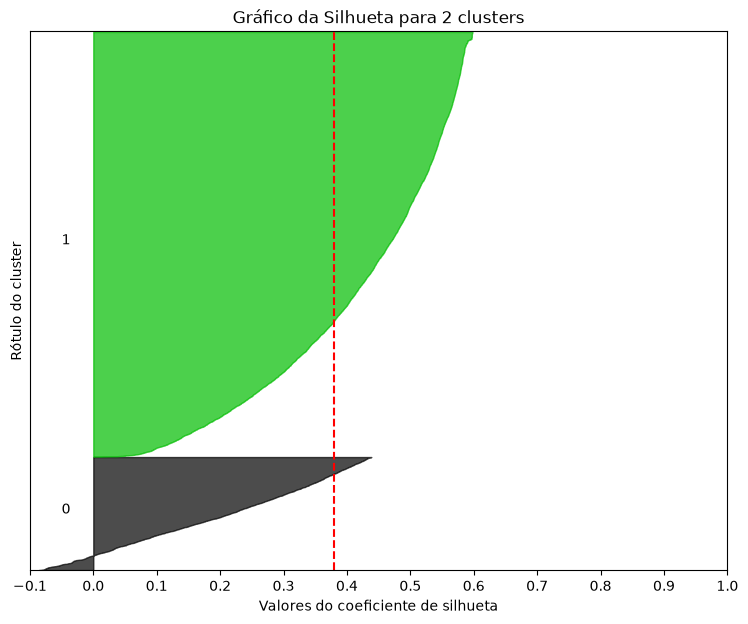

In [43]:
graf_silhueta(2, dados)

In [44]:
def plot_cotovelo(inercia):
  plt.figure(figsize=(8,4))
  plt.plot(range(2,21),inercia,'bo-')
  plt.xlabel('Número de clusters')
  plt.ylabel('Inércia')
  plt.title('Método do Cotovelo para Determinação de k')
  plt.show()

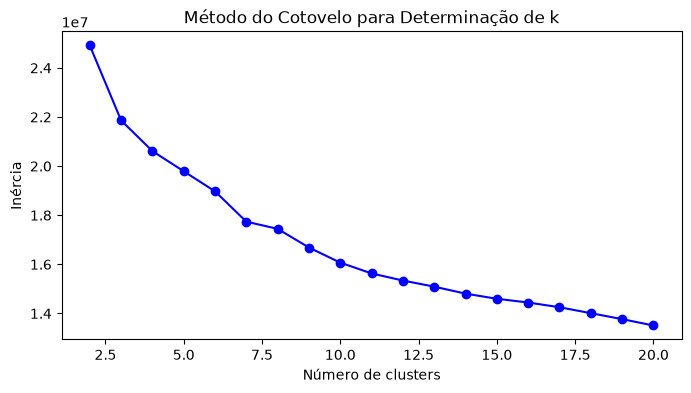

In [45]:
plot_cotovelo(inercia)

In [47]:
dados.describe()

,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_F,sexo_M,sexo_NE
count,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,...,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000
mean,26.852679,31.283790,3.063424,2.927186,2.536946,1.836515,1.641010,1.548645,1.207666,1.198430,...,1.340055,2.977986,4.094828,1.720289,0.819735,0.589594,1.050647,0.761469,0.166256,0.072275
std,1.203746,35.891178,8.374443,7.431099,9.810703,7.881526,6.818708,5.862203,5.376673,5.558905,...,4.934874,7.479126,7.670547,5.092112,3.799795,2.999547,4.492218,0.426202,0.372325,0.258953
min,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,27.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,28.000000,45.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,30.000000,605.000000,220.000000,90.000000,220.000000,170.000000,140.000000,310.000000,80.000000,140.000000,...,70.000000,120.000000,110.000000,80.000000,80.000000,80.000000,80.000000,1.000000,1.000000,1.000000


In [49]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

dados_escalados = scaler.fit_transform(dados)

In [50]:
dados_escalados

array([[0.66666667, 0.08099174, 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.66666667, 0.0677686 , 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.55555556, 0.00165289, 0.        , ..., 1.        , 0.        ,
        0.        ],
       ...,
       [0.66666667, 0.05289256, 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.66666667, 0.03305785, 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.44444444, 0.04132231, 0.        , ..., 1.        , 0.        ,
        0.        ]], shape=(12992, 29))

In [51]:
dados_escalados = pd.DataFrame(dados_escalados, columns=dados.columns)
dados_escalados.describe()

,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_F,sexo_M,sexo_NE
count,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,...,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000,12992.000000
mean,0.650298,0.051709,0.013925,0.032524,0.011532,0.010803,0.011721,0.004996,0.015096,0.008560,...,0.019144,0.024817,0.037226,0.021504,0.010247,0.007370,0.013133,0.761469,0.166256,0.072275
std,0.133750,0.059324,0.038066,0.082568,0.044594,0.046362,0.048705,0.018910,0.067208,0.039706,...,0.070498,0.062326,0.069732,0.063651,0.047497,0.037494,0.056153,0.426202,0.372325,0.258953
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.555556,0.008264,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,0.666667,0.034711,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,0.777778,0.074380,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.090909,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [53]:
silhueta, inercia = avaliacao(dados_escalados)
silhueta

['k=2 - 0.6684575483061149',
 'k=3 - 0.7447500875317523',
 'k=4 - 0.30530680533895693',
 'k=5 - 0.30744468106291023',
 'k=6 - 0.3112387030023592',
 'k=7 - 0.3085860859611137',
 'k=8 - 0.31977796242870504',
 'k=9 - 0.22706218374995277',
 'k=10 - 0.22472400849594734',
 'k=11 - 0.22798574383673903',
 'k=12 - 0.2255502754976101',
 'k=13 - 0.16185795333037842',
 'k=14 - 0.1629865017307575',
 'k=15 - 0.16552254369386465',
 'k=16 - 0.16673895280847542',
 'k=17 - 0.16384282247396847',
 'k=18 - 0.16521943288325647',
 'k=19 - 0.1652810286868148',
 'k=20 - 0.1500107504422225']

Valor médio para 3 clusters: 0.745


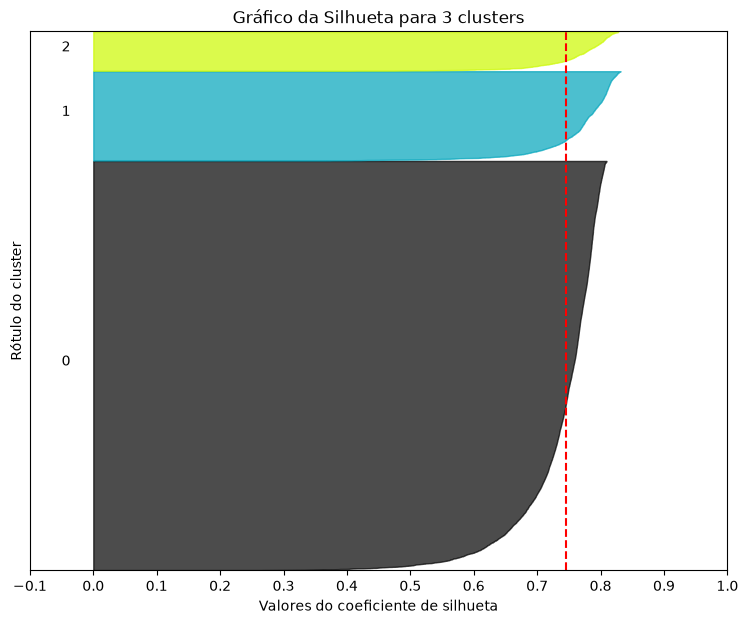

In [54]:
graf_silhueta(3, dados_escalados)

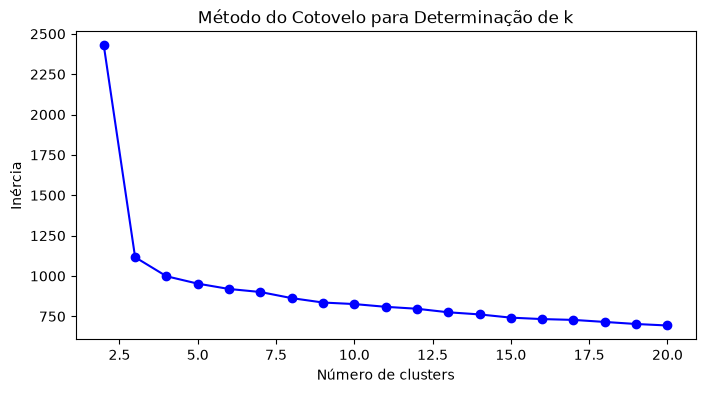

In [55]:
plot_cotovelo(inercia)

In [56]:
modelo_kmeans = KMeans(n_clusters = 3, random_state = 45, n_init = 'auto')
modelo_kmeans.fit(dados_escalados)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",45
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 29)","

In [57]:
joblib.dump(modelo_kmeans, 'kmeans.pkl')

['kmeans.pkl']

In [58]:
dados_analise = pd.DataFrame()

dados_analise[dados_escalados.columns] = scaler.inverse_transform(dados_escalados)

dados_analise

,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_F,sexo_M,sexo_NE
0,27.0,49.0,0.0,0.0,10.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,10.0,1.0,0.0,0.0
1,27.0,41.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,...,0.0,10.0,0.0,0.0,0.0,0.0,10.0,1.0,0.0,0.0
2,26.0,1.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,30.0,0.0,0.0,0.0,1.0,0.0,0.0
3,28.0,32.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,28.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12987,26.0,21.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,20.0,0.0,0.0,0.0,1.0,0.0,0.0
12988,26.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
12989,27.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
12990,27.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [59]:
dados_analise['cluster'] = modelo_kmeans.labels_

In [60]:
cluster_media = dados_analise.groupby('cluster').mean()

cluster_media.T

cluster,0,1,2
idade,26.787830,27.031944,27.123536
numero_de_amigos,32.382796,26.173611,31.460064
basquete,2.959668,3.763889,2.545261
futebol_americano,2.462347,5.347222,2.257721
futebol,2.567472,2.592593,2.087327
softbol,2.273325,0.097222,1.235357
voleibol,1.935712,0.453704,1.267306
natacao,1.693116,0.976852,1.341853
animacao,1.441423,0.092593,1.309904
beisebol,0.792480,3.231481,0.798722


In [61]:
cluster_media = cluster_media.transpose()

cluster_media.columns = [0,1,2]

In [62]:
cluster_media

,0,1,2
idade,26.787830,27.031944,27.123536
numero_de_amigos,32.382796,26.173611,31.460064
basquete,2.959668,3.763889,2.545261
futebol_americano,2.462347,5.347222,2.257721
futebol,2.567472,2.592593,2.087327
softbol,2.273325,0.097222,1.235357
voleibol,1.935712,0.453704,1.267306
natacao,1.693116,0.976852,1.341853
animacao,1.441423,0.092593,1.309904
beisebol,0.792480,3.231481,0.798722


In [63]:

cluster_media[0].sort_values(ascending=False)


numero_de_amigos     32.382796
idade                26.787830
musica                8.541393
cabelo                5.626200
danca                 5.463459
compras               4.943900
fofo                  4.413221
banda                 3.368038
shopping              3.260892
basquete              2.959668
rock                  2.799960
futebol               2.567472
futebol_americano     2.462347
softbol               2.273325
voleibol              1.935712
roupas                1.934701
natacao               1.693116
vestido               1.577883
esportes              1.540483
animacao              1.441423
bebidas               1.078540
sexo_F                1.000000
tenis                 0.930961
nossa_marca           0.893561
beisebol              0.792480
marca_concorrente     0.670171
marcha                0.487213
sexo_M                0.000000
sexo_NE               0.000000
Name: 0, dtype: float64

In [64]:
cluster_media[1].sort_values(ascending=False)


idade                27.031944
numero_de_amigos     26.173611
musica                8.180556
futebol_americano     5.347222
banda                 4.120370
basquete              3.763889
beisebol              3.231481
rock                  3.148148
futebol               2.592593
danca                 2.578704
esportes              2.384259
cabelo                2.009259
shopping              1.652778
tenis                 1.296296
sexo_M                1.000000
natacao               0.976852
bebidas               0.949074
roupas                0.861111
fofo                  0.847222
marcha                0.527778
compras               0.523148
voleibol              0.453704
nossa_marca           0.425926
vestido               0.384259
marca_concorrente     0.263889
softbol               0.097222
animacao              0.092593
sexo_F                0.000000
sexo_NE               0.000000
Name: 1, dtype: float64

In [65]:
cluster_media[2].sort_values(ascending=False)


numero_de_amigos     31.460064
idade                27.123536
musica                7.103301
danca                 4.749734
cabelo                4.345048
fofo                  3.642173
compras               3.365282
shopping              3.045793
banda                 2.758253
basquete              2.545261
futebol_americano     2.257721
futebol               2.087327
rock                  1.916933
roupas                1.437700
natacao               1.341853
animacao              1.309904
voleibol              1.267306
softbol               1.235357
tenis                 1.150160
vestido               1.033014
sexo_NE               1.000000
esportes              0.990415
bebidas               0.990415
nossa_marca           0.947817
beisebol              0.798722
marca_concorrente     0.489883
marcha                0.351438
sexo_F                0.000000
sexo_M                0.000000
Name: 2, dtype: float64